In [3]:
from sklearn.model_selection import train_test_split
import pandas as pd


student_df = pd.read_csv('../data/raw/student_mental_health.csv')

X = student_df.drop(columns=["Student_ID", "Mental_Health_Risk", "Risk_Encoded"], errors='ignore')
y = student_df['Mental_Health_Risk']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Shape X_train :", X_train.shape)
print("Shape X_test  :", X_test.shape)

Shape X_train : (1600, 15)
Shape X_test  : (400, 15)


In [4]:
ordinal_cols = ["Physical_Activity", "Diet_Quality"]
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.drop(ordinal_cols).tolist()

print(f"Variables numériques ({len(num_cols)}) :", num_cols)
print(f"Variables catégorielles ({len(cat_cols)}) :", cat_cols)


Variables numériques (10) : ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Variables catégorielles (3) : ['Gender', 'Part_Time_Job', 'Previous_Mental_Health_History']


In [5]:
import numpy as np 


for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    X_train[col] = np.clip(X_train[col], lower_bound, upper_bound)
    X_test[col] = np.clip(X_test[col], lower_bound, upper_bound)

print("Traitement des valeurs aberrantes (IQR Capping) effectué avec succès.")

Traitement des valeurs aberrantes (IQR Capping) effectué avec succès.


In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder,LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline



num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
            categories=[
                ['Low', 'Moderate', 'High'],
                ["Poor", "Average", "Good"]
            ],
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])


label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)



preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('ordinal', ordinal_pipeline, ordinal_cols),
    ('cat', cat_pipeline, cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

Classes encodées : {'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}


In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    'KNN':KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=1),
}

trained_models = {}

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    trained_models[name] = model

In [11]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score
)

predictions = {}
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_processed)
    y_proba = model.predict_proba(X_test_processed)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    })

results_df = pd.DataFrame(results).sort_values("F1-Score", ascending=False).reset_index(drop=True)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.7075,0.7089,0.7075,0.7081
1,KNN,0.5925,0.5827,0.5925,0.5862
2,Decision Tree,0.5825,0.5843,0.5825,0.5833



=== KNN ===
              precision    recall  f1-score   support

         Low       0.66      0.70      0.68       132
      Medium       0.44      0.38      0.41       132
        High       0.64      0.70      0.67       136

    accuracy                           0.59       400
   macro avg       0.58      0.59      0.59       400
weighted avg       0.58      0.59      0.59       400


=== Decision Tree ===
              precision    recall  f1-score   support

         Low       0.67      0.65      0.66       132
      Medium       0.47      0.48      0.48       132
        High       0.61      0.61      0.61       136

    accuracy                           0.58       400
   macro avg       0.58      0.58      0.58       400
weighted avg       0.58      0.58      0.58       400


=== Random Forest ===
              precision    recall  f1-score   support

         Low       0.80      0.77      0.78       132
      Medium       0.57      0.58      0.57       132
        High    

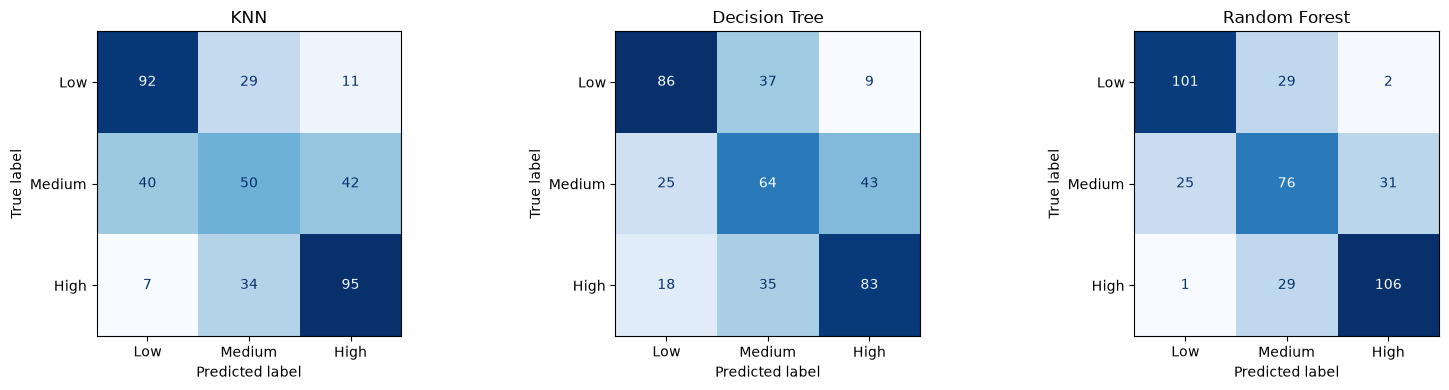

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

class_order = ["Low", "Medium", "High"]

for name in trained_models:
    print(f"\n=== {name} ===")
    print(classification_report(y_test, predictions[name], labels=class_order, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, model) in zip(axes, trained_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test_processed, y_test,
        labels=class_order, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

promising_models = {
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "KNN": KNeighborsClassifier()
}

param_grids = {
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [8, 12, None],
        "model__min_samples_split": [2, 5]
    },
    "KNN": {
        "model__n_neighbors": [3, 5, 7, 9, 11]
    }
}

optimized_models = {}
tuning_results = []

for name, model in promising_models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    grid = GridSearchCV(
        pipe,
        param_grids[name],
        cv=5,
        scoring="f1_weighted",
        n_jobs=-1
    )
    grid.fit(X_train, y_train)
    optimized_models[name] = grid.best_estimator_
    tuning_results.append({
        "Model": name,
        "Best CV F1-Score": grid.best_score_,
        "Best Params": grid.best_params_
    })

tuning_df = pd.DataFrame(tuning_results).sort_values("Best CV F1-Score", ascending=False).reset_index(drop=True)
display(tuning_df)

,Model,Best CV F1-Score,Best Params
0,Random Forest,0.679012,"{'model__max_depth': 8, 'model__min_samples_sp..."
1,KNN,0.634648,{'model__n_neighbors': 9}
